# Project 3 — Optimizing PINN Training for 1-D Viscous Burgers

**Path C:** diagnose a PINN failure and demonstrate a targeted optimizer fix.

We study

$$u_t + u u_x - \nu u_{xx}=0,\qquad x\in[-1,1],\ t\in[0,1],$$

with $u(x,0)=-\sin(\pi x)$ and $u(-1,t)=u(1,t)=0$.

The difficulty knob is viscosity $\nu$: decreasing $\nu$ creates a sharper internal layer. The controlled fix changes only the optimization strategy from **Adam** to **Adam → L-BFGS**.

## Data

The public validation file is the classic `burgers_shock.mat` from the original PINN Burgers example. It is only about 203 KB and contains `x`, `t`, and `usol`.

From the repository root, download it with:

```bash
python src/download_data.py
```

The project also generates independent finite-volume references in `.npz` and `.mat` format so the computational experiment is reproducible without the external file.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / "results").exists() and (ROOT.parent / "results").exists():
    ROOT = ROOT.parent
print("Project root:", ROOT)

Project root: /mnt/data/burgers_pinn_project


## Reproduce everything

Set `RUN_FULL=True` to rerun the finite-volume references, all six PINN trainings, the capacity diagnostic, and the plots. The checked-in results below were generated with seed 0.

In [2]:
RUN_FULL = False
if RUN_FULL:
    import subprocess, sys
    subprocess.run([sys.executable, str(ROOT / "run_all.py")], cwd=ROOT, check=True)

## P1/P3/P5 — quantitative results

In [3]:
metrics = pd.read_csv(ROOT / "results" / "metrics.csv")
metrics

,nu,nu_tag,method,relative_l2,train_seconds,inference_seconds
0,0.050000,0p05,finite_volume_257,0.005703,0.000000,0.014852
1,0.050000,0p05,PINN_Adam,0.139053,3.126294,0.026038
2,0.050000,0p05,PINN_Adam_LBFGS,0.013276,3.925517,0.019998
3,0.010000,0p01,finite_volume_257,0.013073,0.000000,0.018830
4,0.010000,0p01,PINN_Adam,0.383511,3.379001,0.012084
5,0.010000,0p01,PINN_Adam_LBFGS,0.157590,3.901389,0.010937
6,0.003183,0.01_over_pi,finite_volume_257,0.023114,0.000000,0.017984
7,0.003183,0.01_over_pi,PINN_Adam,0.425414,3.078023,0.011676
8,0.003183,0.01_over_pi,PINN_Adam_LBFGS,0.285920,3.924009,0.009339
9,0.003183,0.01_over_pi,supervised_capacity_test,0.055668,7.457787,0.008418


In [4]:
table = metrics[metrics.method.isin(["finite_volume_257","PINN_Adam","PINN_Adam_LBFGS"])].pivot(
    index="nu", columns="method", values="relative_l2"
).sort_index(ascending=False)
table

method,PINN_Adam,PINN_Adam_LBFGS,finite_volume_257
nu,,,
0.050000,0.139053,0.013276,0.005703
0.010000,0.383511,0.157590,0.013073
0.003183,0.425414,0.285920,0.023114


### Main result

- At $
u=0.05$, Adam → L-BFGS reduces PINN error by about **90%**.
- At $
u=0.01$, the reduction is about **59%**.
- At $
u=0.01/\pi$, the reduction is about **33%**.

The conventional solver remains the correct choice for a single forward solve.

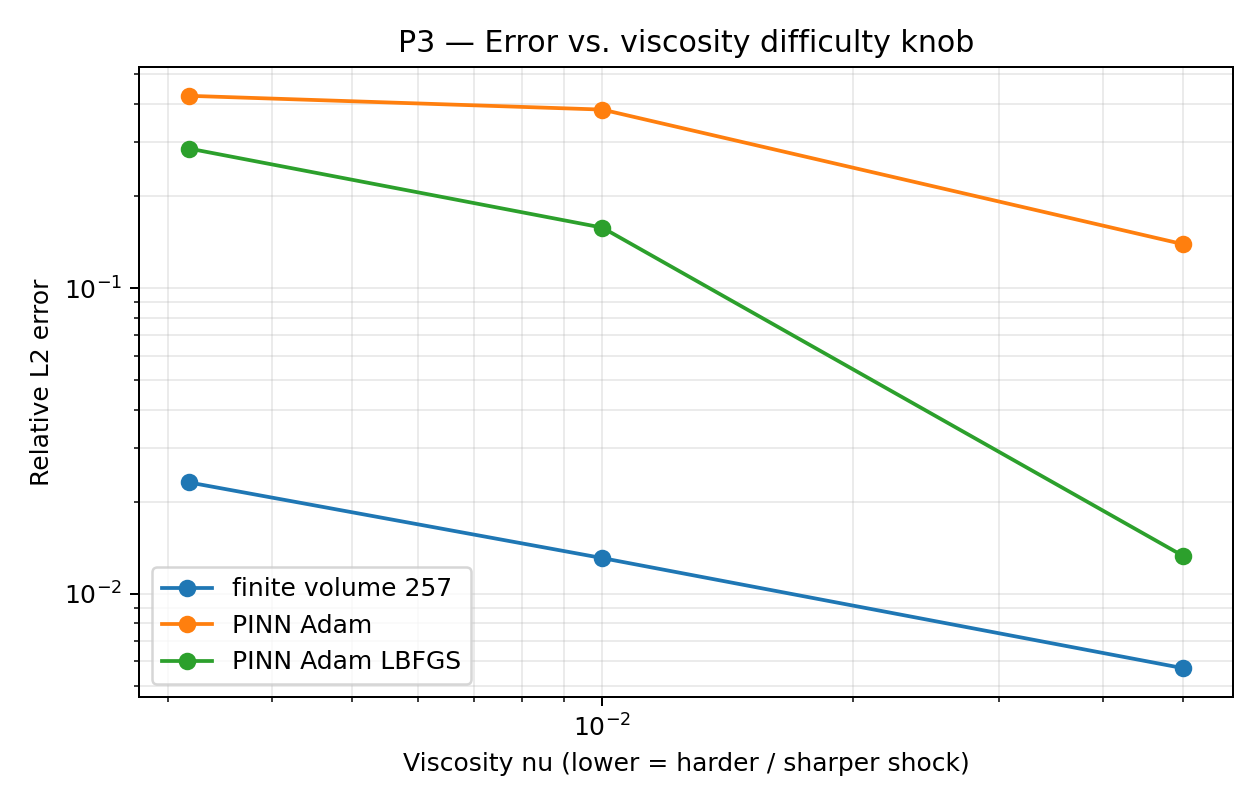

In [5]:
display(Image(filename=str(ROOT / "figures" / "p3_error_vs_viscosity.png")))

## P2 — loss components

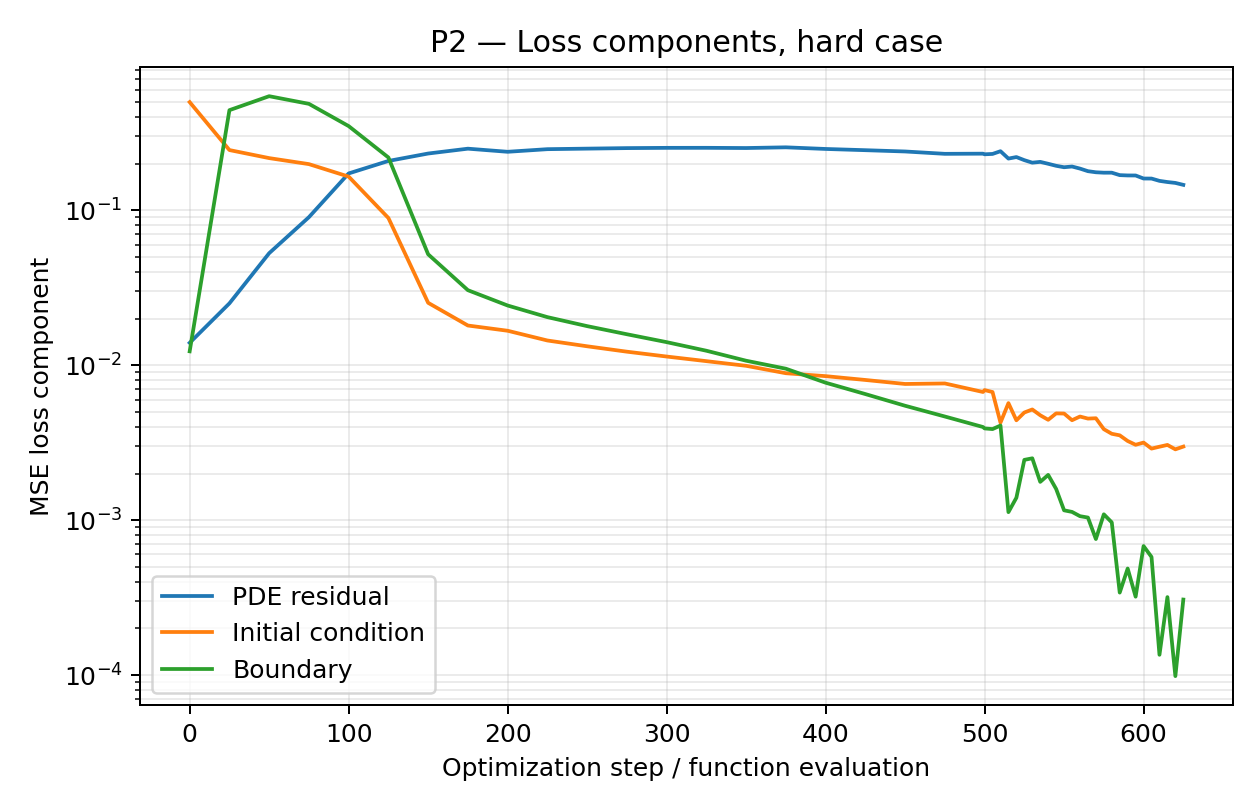

In [6]:
display(Image(filename=str(ROOT / "figures" / "p2_loss_components_hard.png")))

## Diagnosis: expressivity vs. optimization

For the hardest case, the same architecture is fitted directly to 5,000 reference values. This supervised capacity test reaches about **5.6% relative L2 error**, versus about **42.5% for Adam PINN**. The architecture can therefore represent the solution substantially better than the physics-informed optimization finds.

Adding L-BFGS improves the PINN without changing the architecture, points, seed, or loss weights. This supports an optimization-dominated diagnosis, while the remaining sharp-layer error indicates a secondary high-frequency limitation.

In [7]:
hard = metrics[np.isclose(metrics.nu, 0.01/np.pi)][["method","relative_l2","train_seconds"]]
hard

,method,relative_l2,train_seconds
6,finite_volume_257,0.023114,0.000000
7,PINN_Adam,0.425414,3.078023
8,PINN_Adam_LBFGS,0.285920,3.924009
9,supervised_capacity_test,0.055668,7.457787


## P4 — where the error lives

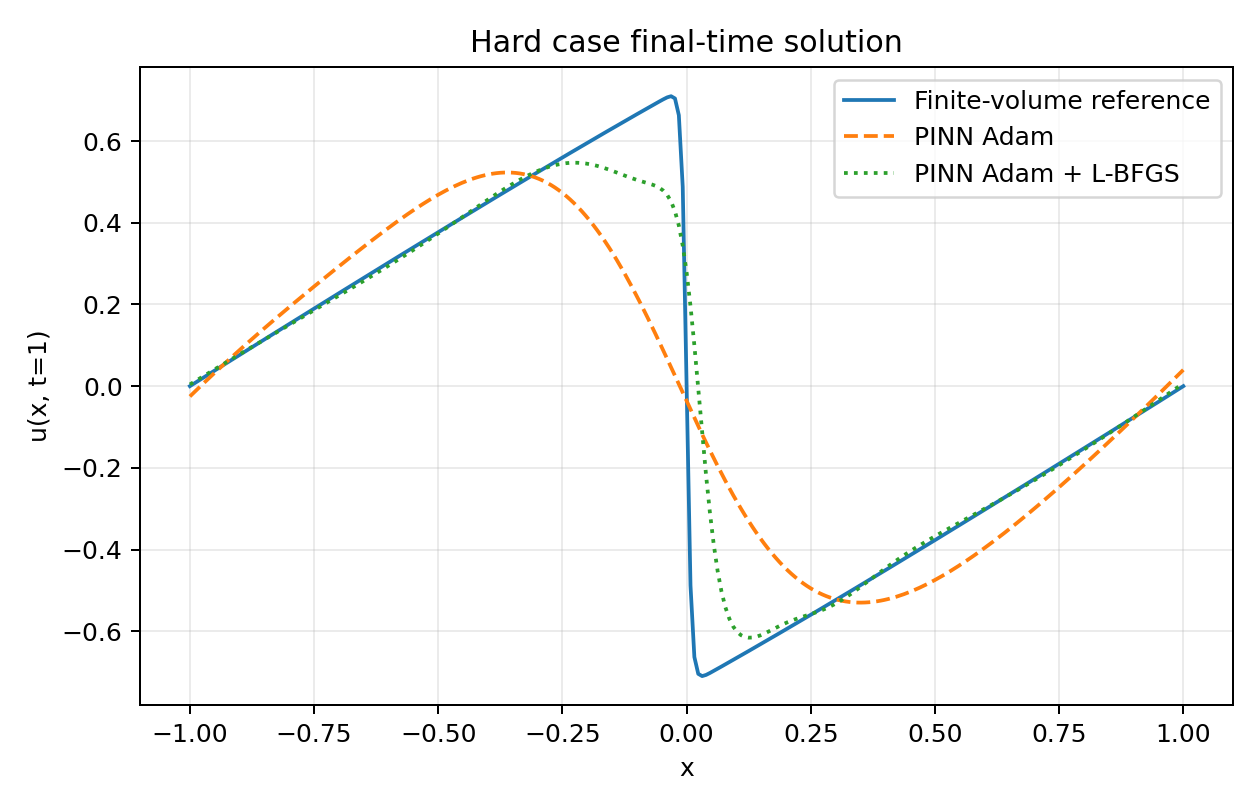

In [8]:
display(Image(filename=str(ROOT / "figures" / "hard_case_final_time.png")))

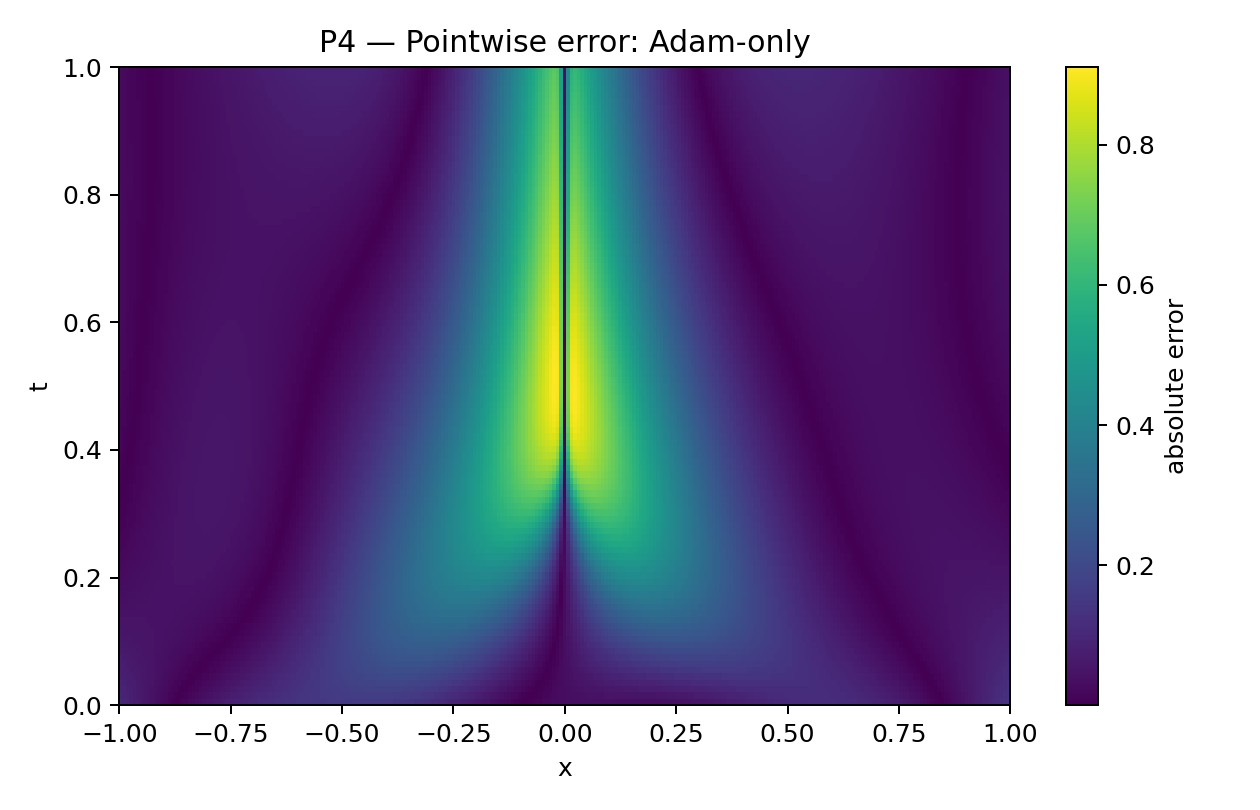

In [9]:
display(Image(filename=str(ROOT / "figures" / "p4_error_field_adam.png")))

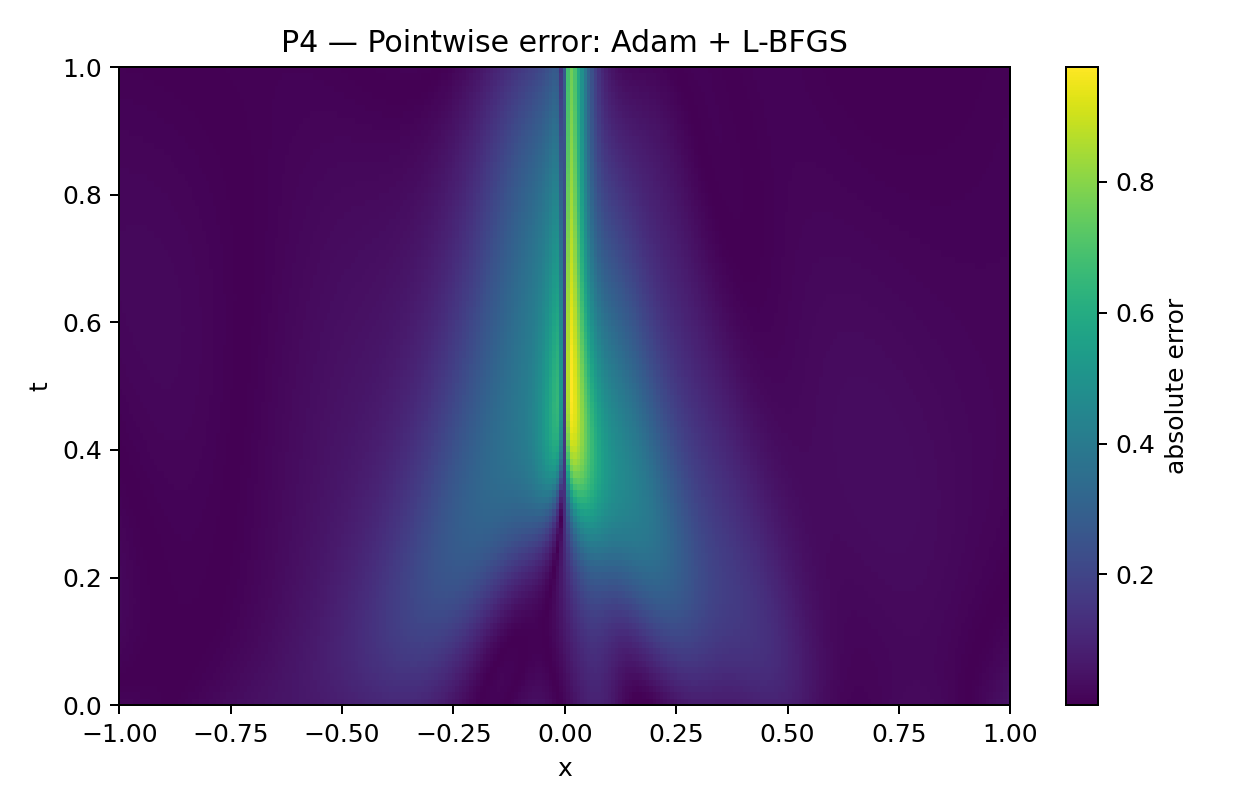

In [10]:
display(Image(filename=str(ROOT / "figures" / "p4_error_field_adam_lbfgs.png")))

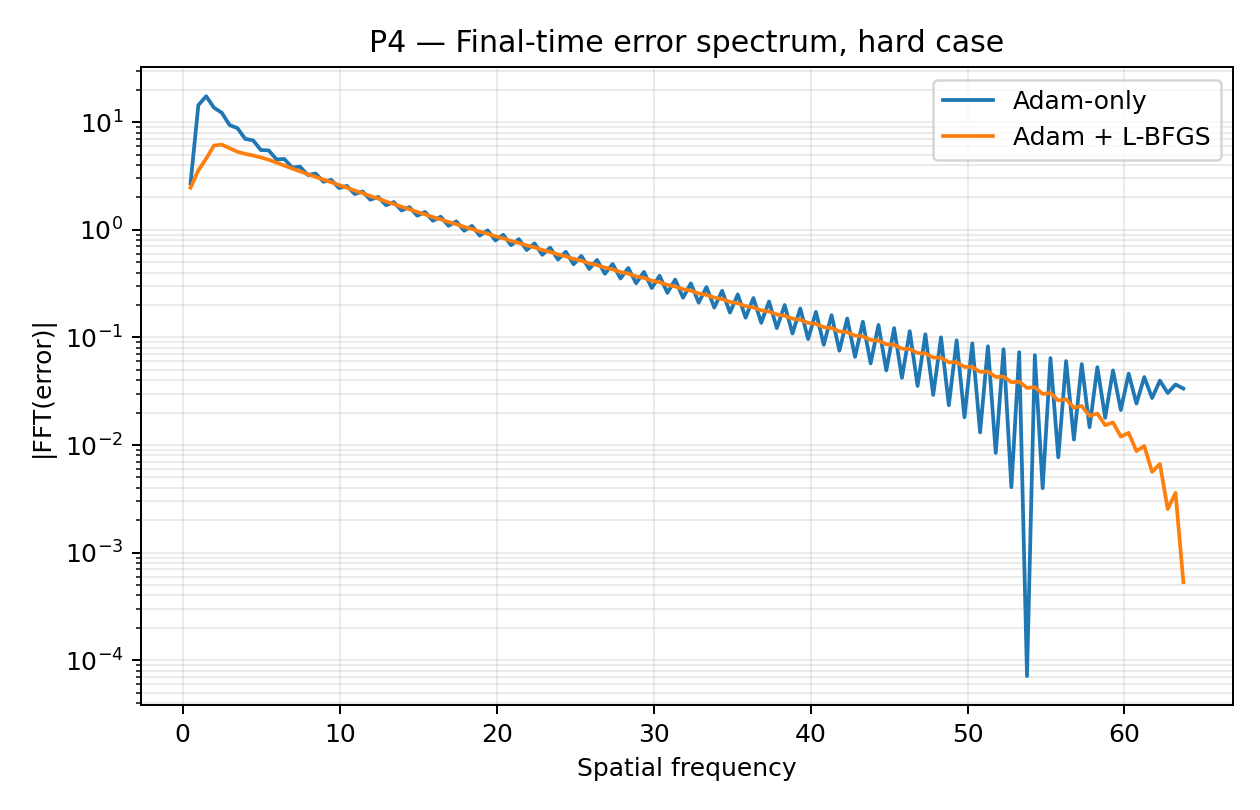

In [11]:
display(Image(filename=str(ROOT / "figures" / "p4_error_spectrum_hard.png")))

## Recommendation

Do **not** replace a conventional solver with a basic PINN for this single forward PDE. If the research application has an inverse/sparse-data reason to use a PINN, use a stronger optimizer than Adam alone and validate on a conventional reduced case. The next controlled improvement should target the residual high-frequency error using Fourier features or residual-adaptive sampling.

## Researcher-specific material

The computational study is complete, but the course requires a real interview. Do not fabricate that section. Fill `OUTREACH_AND_INTERVIEW.md`, then adapt `RECOMMENDATION_MEMO.md` to the researcher's PDE, current solver cost, required accuracy, and decision context.